# Video Game Sales Correlations

## Part 1: Load and Clean Data

In [1]:
import pandas as pd

df = pd.read_csv("video_game_sales.csv")

sales_columns = [
    "NA_Sales", "EU_Sales", "JP_Sales",
    "Other_Sales", "Global_Sales"
]

sales_df = df[sales_columns].dropna()

sales_df.head()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,41.49,29.02,3.77,8.46,82.74
1,29.08,3.58,6.81,0.77,40.24
2,15.85,12.88,3.79,3.31,35.82
3,15.75,11.01,3.28,2.96,33.00
4,11.27,8.89,10.22,1.00,31.37


## Part 2: Correlation Matrix

In [2]:
correlation_matrix = sales_df.corr(method="pearson")

correlation_matrix

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,1.000000,0.767727,0.449787,0.634737,0.941047
EU_Sales,0.767727,1.000000,0.435584,0.726385,0.902836
JP_Sales,0.449787,0.435584,1.000000,0.290186,0.611816
Other_Sales,0.634737,0.726385,0.290186,1.000000,0.748331
Global_Sales,0.941047,0.902836,0.611816,0.748331,1.000000


### Strongest and Weakest Correlations

Identify the strongest and weakest correlations between different sales regions. Exclude self-correlations and duplicate pairs.

In [3]:
import numpy as np

# Exclude self-correlations and duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

pairs = upper_triangle.stack()

\
strongest = pairs.idxmax()
weakest = pairs.abs().idxmin()

print("Strongest:", strongest, round(pairs[strongest], 4))
print("Weakest:", weakest, round(pairs[weakest], 4))

Strongest: ('NA_Sales', 'Global_Sales') 0.941
Weakest: ('JP_Sales', 'Other_Sales') 0.2902


## Part 3: Correlation Heatmap

Visualize the correlations between regional and global video game sales.

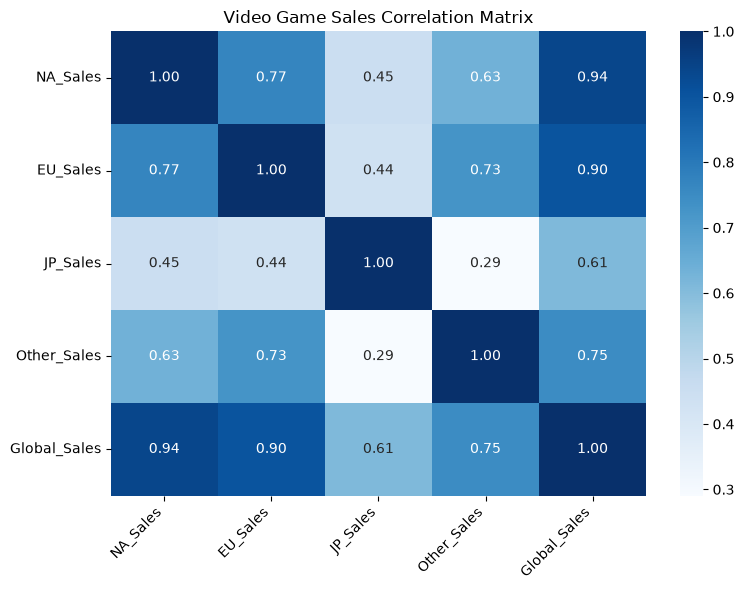

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Video Game Sales Correlation Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Part 4: Market Interpretation Summary

The results show a strong positive correlation between North American sales and global sales (0.94). This means games that sell well in North America also tend to have higher worldwide sales. European sales also have a strong correlation with global sales (0.90). Since both regions contribute to global sales, their sales numbers have a strong relationship with worldwide performance.

The weakest correlation is between Japan and other regions (0.29). This shows that a game selling well in Japan doesn't always mean it will sell well in other markets. Differences in gaming preferences, popular consoles, and regional audiences may explain this weaker relationship. Overall, the results show that video game sales are connected across markets, but regional preferences can affect how games perform.